In [1]:
# ============================================================
# California Employment Trends by Industry (2019–2024)
# Author: Tannaz Haghi
# Data Source: Bureau of Labor Statistics (BLS) API
# ============================================================

import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns
import requests

/Users/tannazhaghi/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [2]:
# BLS API Key
API_KEY = "64143b73934d4d95817a9ded84c0d868"  # Replace with your actual key

series_ids = {
    "SMU06000007000000001": "Total Nonfarm",
    "SMU06000005500000001": "Leisure & Hospitality",
    "SMU06000006500000001": "Healthcare",
    "SMU06000005000000001": "Retail Trade",
    "SMU06000006054000001": "Tech / Information",
}

In [3]:
def fetch_bls_series(series_id, start_year="2019", end_year="2024"):
    url = "https://api.bls.gov/publicAPI/v2/timeseries/data/"
    payload = {
        "seriesid": [series_id],
        "startyear": start_year,
        "endyear": end_year,
        "registrationkey": API_KEY
    }
    response = requests.post(url, json=payload)
    data = response.json()["Results"]["series"][0]["data"]
    df = pd.DataFrame(data)
    df["series_id"] = series_id
    return df

# Fetch all industries and combine into one table
frames = []
for sid, label in series_ids.items():
    df = fetch_bls_series(sid)
    df["industry"] = label
    frames.append(df)

raw_df = pd.concat(frames, ignore_index=True)
print(f"Rows fetched: {len(raw_df)}")
raw_df.head()

Rows fetched: 360


,year,period,periodName,value,footnotes,series_id,industry
0,2024,M12,December,2005.3,[{}],SMU06000007000000001,Total Nonfarm
1,2024,M11,November,2014.2,[{}],SMU06000007000000001,Total Nonfarm
2,2024,M10,October,2027.7,[{}],SMU06000007000000001,Total Nonfarm
3,2024,M09,September,2009.0,[{}],SMU06000007000000001,Total Nonfarm
4,2024,M08,August,2036.1,[{}],SMU06000007000000001,Total Nonfarm


In [4]:
# Save raw data as backup before cleaning
raw_df.to_csv("data/raw_bls_data.csv", index=False)
print("Raw data saved ✓")

Raw data saved ✓


In [5]:
# Clean the data
df = raw_df.copy()

# Keep only monthly rows (remove annual averages)
df = df[df["period"].str.startswith("M")]

# Convert columns to proper types
df["year"] = df["year"].astype(int)
df["month"] = df["period"].str.replace("M", "").astype(int)
df["employment"] = pd.to_numeric(df["value"], errors="coerce")

# Create a proper date column
df["date"] = pd.to_datetime(df[["year", "month"]].assign(day=1))

# Keep only the columns we need
df = df[["date", "year", "month", "industry", "employment"]]

# Drop any rows with missing employment values
df = df.dropna(subset=["employment"])

print(f"Rows after cleaning: {len(df)}")
print(f"Date range: {df['date'].min()} to {df['date'].max()}")
print(f"Industries: {df['industry'].unique()}")
df.head()

Rows after cleaning: 360
Date range: 2019-01-01 00:00:00 to 2024-12-01 00:00:00
Industries: ['Total Nonfarm' 'Leisure & Hospitality' 'Healthcare' 'Retail Trade'
 'Tech / Information']


,date,year,month,industry,employment
0,2024-12-01,2024,12,Total Nonfarm,2005.3
1,2024-11-01,2024,11,Total Nonfarm,2014.2
2,2024-10-01,2024,10,Total Nonfarm,2027.7
3,2024-09-01,2024,9,Total Nonfarm,2009.0
4,2024-08-01,2024,8,Total Nonfarm,2036.1


In [6]:
# Check if Tech series returned any data
for sid, label in series_ids.items():
    subset = raw_df[raw_df["series_id"] == sid]
    print(f"{label}: {len(subset)} rows")

Total Nonfarm: 72 rows
Leisure & Hospitality: 72 rows
Healthcare: 72 rows
Retail Trade: 72 rows
Tech / Information: 72 rows


In [7]:
# Test alternative series IDs for Information/Tech sector in California
test_ids = {
    "SMU06000005054000001": "Tech (original)",
    "SMS06000005054000001": "Tech (SMS prefix)",
    "SMU06000005000000001": "Information CA",
    "SMU06000005100000001": "Information v2",
}

for sid, label in test_ids.items():
    url = "https://api.bls.gov/publicAPI/v2/timeseries/data/"
    payload = {
        "seriesid": [sid],
        "startyear": "2019",
        "endyear": "2024",
        "registrationkey": API_KEY
    }
    response = requests.post(url, json=payload)
    result = response.json()
    rows = len(result["Results"]["series"][0]["data"])
    print(f"{label} ({sid}): {rows} rows")

Tech (original) (SMU06000005054000001): 0 rows
Tech (SMS prefix) (SMS06000005054000001): 0 rows
Information CA (SMU06000005000000001): 72 rows
Information v2 (SMU06000005100000001): 0 rows


In [8]:
# Test correct Information sector codes for California
test_ids = {
    "SMU06000005050000001": "Information v3",
    "SMU06000005055000001": "Information v4", 
    "SMU06000005056000001": "Information v5",
    "SMU06000006054000001": "Information v6",
}

for sid, label in test_ids.items():
    url = "https://api.bls.gov/publicAPI/v2/timeseries/data/"
    payload = {
        "seriesid": [sid],
        "startyear": "2019",
        "endyear": "2024",
        "registrationkey": API_KEY
    }
    response = requests.post(url, json=payload)
    result = response.json()
    rows = len(result["Results"]["series"][0]["data"])
    print(f"{label} ({sid}): {rows} rows")

Information v3 (SMU06000005050000001): 0 rows
Information v4 (SMU06000005055000001): 0 rows
Information v5 (SMU06000005056000001): 0 rows
Information v6 (SMU06000006054000001): 72 rows


In [9]:
print(f"Total rows: {len(df)}")
print(f"Industries: {df['industry'].value_counts()}")

Total rows: 360
Industries: industry
Total Nonfarm            72
Leisure & Hospitality    72
Healthcare               72
Retail Trade             72
Tech / Information       72
Name: count, dtype: int64


In [10]:
# Save cleaned data to SQLite database
conn = sqlite3.connect("ca_employment.db")
df.to_sql("employment", conn, if_exists="replace", index=False)
print("Data saved to ca_employment.db ✓")

Data saved to ca_employment.db ✓


In [11]:
# SQL Query 1: Which industry had the steepest job loss in 2020?
q1 = """
    SELECT 
        industry,
        ROUND(AVG(CASE WHEN year = 2019 THEN employment END), 1) AS avg_2019,
        ROUND(AVG(CASE WHEN year = 2020 THEN employment END), 1) AS avg_2020,
        ROUND(
            (AVG(CASE WHEN year = 2020 THEN employment END) - 
             AVG(CASE WHEN year = 2019 THEN employment END)) /
             AVG(CASE WHEN year = 2019 THEN employment END) * 100
        , 1) AS pct_change
    FROM employment
    GROUP BY industry
    ORDER BY pct_change ASC
"""

q1_result = pd.read_sql(q1, conn)
q1_result

,industry,avg_2019,avg_2020,pct_change
0,Total Nonfarm,2034.3,1481.8,-27.2
1,Retail Trade,567.2,540.5,-4.7
2,Leisure & Hospitality,840.0,816.4,-2.8
3,Healthcare,2806.8,2737.7,-2.5
4,Tech / Information,1331.4,1301.6,-2.2


In [ ]:
# Total Nonfarm dropped 27.2% — that's the overall California economy taking a massive hit in 2020
# Retail Trade dropped 4.7% — second hardest hit
# Leisure & Hospitality dropped 2.8% — surprising it's not worse, but remember this is an average across all 12 months of 2020, so the summer/fall recovery softens the spring crash
# Healthcare dropped 2.5% — people avoided hospitals during COVID
# Tech / Information only dropped 2.2% — most resilient, which makes sense as tech went remote easily

In [12]:
# SQL Query 2: Which industries recovered to pre-COVID levels by 2022?
q2 = """
    SELECT
        industry,
        ROUND(AVG(CASE WHEN year = 2019 THEN employment END), 1) AS baseline_2019,
        ROUND(AVG(CASE WHEN year = 2022 THEN employment END), 1) AS avg_2022,
        CASE 
            WHEN AVG(CASE WHEN year = 2022 THEN employment END) >= 
                 AVG(CASE WHEN year = 2019 THEN employment END)
            THEN 'Recovered'
            ELSE 'Still Below'
        END AS recovery_status
    FROM employment
    GROUP BY industry
    ORDER BY recovery_status
"""

q2_result = pd.read_sql(q2, conn)
q2_result

,industry,baseline_2019,avg_2022,recovery_status
0,Healthcare,2806.8,2933.7,Recovered
1,Retail Trade,567.2,617.6,Recovered
2,Tech / Information,1331.4,1427.3,Recovered
3,Leisure & Hospitality,840.0,838.7,Still Below
4,Total Nonfarm,2034.3,1931.2,Still Below


In [ ]:
# Healthcare, Retail Trade, and Tech all fully recovered by 2022 — in fact they grew beyond 2019 levels
# Leisure & Hospitality was still barely below — 838.7 vs 840.0 baseline, almost there but not quite
# Total Nonfarm still below — meaning even though individual sectors recovered, the overall economy hadn't fully bounced back by 2022

# While tech and healthcare surpassed pre-COVID employment by 2022, the broader California economy was still recovering.

In [13]:
# SQL Query 3: Year-over-year change using LAG window function
q3 = """
    SELECT
        industry,
        year,
        ROUND(AVG(employment), 1) AS avg_employment,
        ROUND(AVG(employment) - LAG(ROUND(AVG(employment), 1)) 
            OVER (PARTITION BY industry ORDER BY year), 1) AS yoy_change
    FROM employment
    GROUP BY industry, year
    ORDER BY industry, year
"""

q3_result = pd.read_sql(q3, conn)
q3_result

,industry,year,avg_employment,yoy_change
0,Healthcare,2019,2806.8,NaN
1,Healthcare,2020,2737.7,-69.1
2,Healthcare,2021,2817.7,80.0
3,Healthcare,2022,2933.7,116.0
4,Healthcare,2023,3104.6,170.9
5,Healthcare,2024,3300.0,195.4
6,Leisure & Hospitality,2019,840.0,NaN
7,Leisure & Hospitality,2020,816.4,-23.6
8,Leisure & Hospitality,2021,827.3,10.9
9,Leisure & Hospitality,2022,838.7,11.4


In [ ]:
# Healthcare — steady growth every single year, accelerating each year from -69K in 2020 to +195K by 2024. The strongest recovery story in the data.

# Leisure & Hospitality — recovered slightly in 2021-2022 but then started declining again in 2023 and 2024. That's a surprising and interesting finding worth highlighting.

# Retail Trade — recovered strongly in 2021-2022 but then dropped sharply in 2023 (-58K) and continued falling in 2024. Likely reflecting the shift to e-commerce.

# Tech / Information — recovered well through 2022 but then started declining in 2023 and 2024. That's the Bay Area tech layoffs showing up directly in your data.

# Total Nonfarm — the massive -552K drop in 2020 is striking. Recovery has been slow, and by 2024 the year-over-year change is only +7K — almost flat.

# The NaN values in 2019 are expected — LAG has no previous year to compare to, so it returns blank for the first row of each industry.

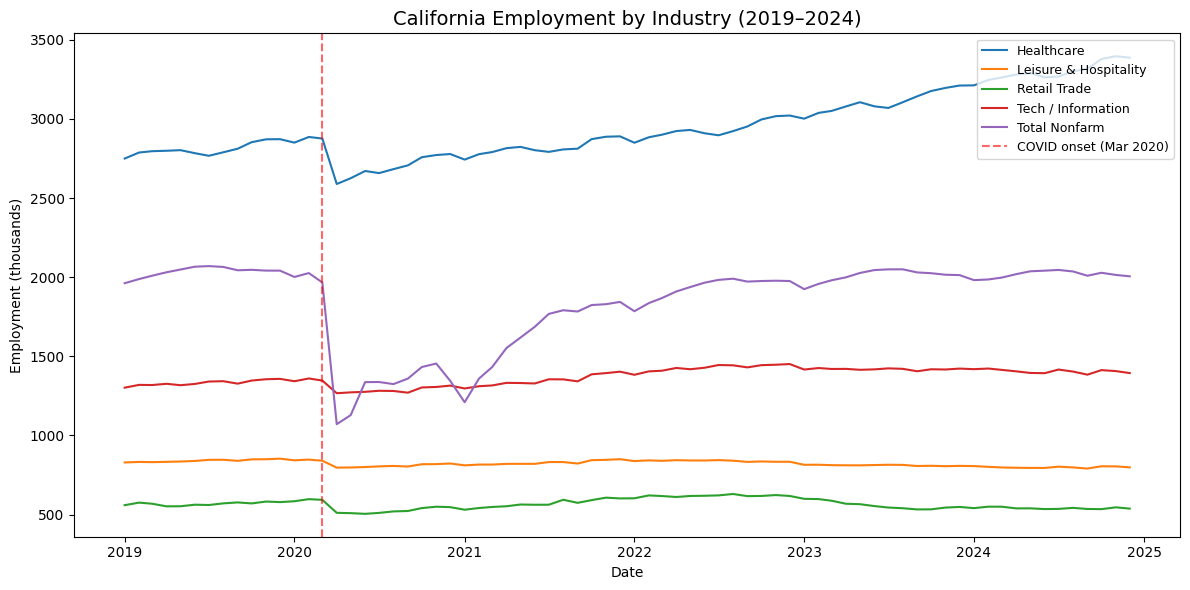

In [14]:
# Visualization 1: Employment over time by industry
fig, ax = plt.subplots(figsize=(12, 6))

for industry, group in df.groupby("industry"):
    group_sorted = group.sort_values("date")
    ax.plot(group_sorted["date"], group_sorted["employment"], label=industry)

ax.axvline(pd.Timestamp("2020-03-01"), color="red", 
           linestyle="--", alpha=0.6, label="COVID onset (Mar 2020)")
ax.set_title("California Employment by Industry (2019–2024)", fontsize=14)
ax.set_xlabel("Date")
ax.set_ylabel("Employment (thousands)")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.savefig("charts/employment_trends.png", dpi=150)
plt.show()

In [ ]:
# Healthcare (blue) — steady upward climb the whole time, barely dipped at COVID and kept growing
# Total Nonfarm (purple) — the dramatic crash at the red line is striking, then slow recovery
# Tech / Information (red) — very stable, slight peak around 2022 then gradual decline — that's the tech layoffs
# Leisure & Hospitality (orange) — flat the whole period, slight dip at COVID
# Retail Trade (green) — flattest line, very stable with a tiny COVID dip

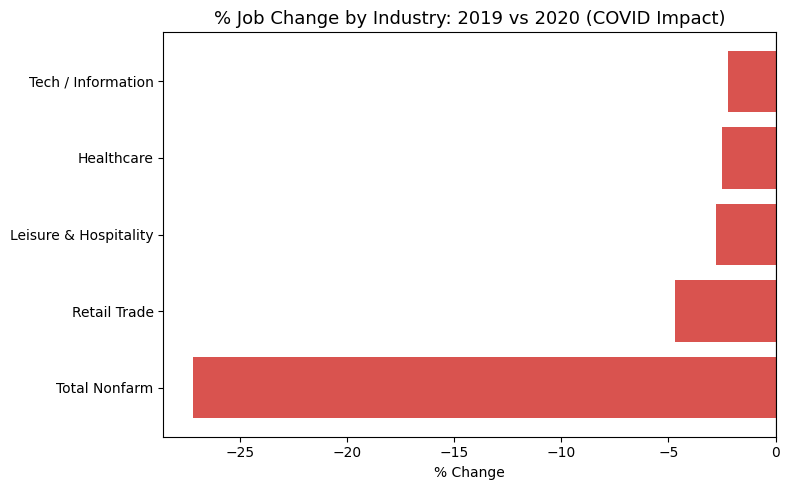

In [15]:
# Visualization 2: % job change by industry 2019 vs 2020
fig, ax = plt.subplots(figsize=(8, 5))

colors = ["#d9534f" if x < 0 else "#5cb85c" for x in q1_result["pct_change"]]
ax.barh(q1_result["industry"], q1_result["pct_change"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("% Job Change by Industry: 2019 vs 2020 (COVID Impact)", fontsize=13)
ax.set_xlabel("% Change")
plt.tight_layout()
plt.savefig("charts/pct_change.png", dpi=150)
plt.show()

In [ ]:
# The Total Nonfarm bar dominates — that -27% drop dwarfs every individual sector, which makes sense because it captures the entire economy including sectors not in this analysis.

In [16]:
# Close database connection
conn.close()
print("Done ✓")

Done ✓


## Key Findings

1. **Total Nonfarm employment dropped 27.2%** in 2020 — the steepest 
   COVID impact of any category tracked, reflecting economy-wide disruption.

2. **Healthcare was the most resilient sector**, dropping only 2.5% in 2020 
   and growing continuously through 2024, adding ~195K jobs year-over-year 
   by 2024.

3. **Tech / Information showed post-layoff softening** — after peaking in 
   2022, employment declined in both 2023 (-8.9K) and 2024 (-13.1K), 
   consistent with Bay Area tech layoff trends.

4. **Leisure & Hospitality never fully recovered** — still declining in 
   2023 and 2024, suggesting structural shifts in the sector post-pandemic.